[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/simonkng/ophthalmology-ml-workshop/blob/main/notebooks/session2/Session2_Evaluating_and_Trusting_Results.ipynb)

> **Public version.** Uses openly available data only (**Harvard-GDP**, CC BY-NC-ND 4.0), downloaded
> directly from its public source when you run the notebook - nothing is redistributed here.
> Runs in Google Colab or Kaggle (no installation) or locally with Python 3.9+.

# Session 2 - Reading Models Critically and Evaluating Results
**Programming in Ophthalmology - Online Workshop (Session 2, 12 November 2026)** - Dr. Simon König

| Part | Topic | Time |
|---|---|---|
| **R** | Recap: rebuild the Session 1 pipeline in a few cells | ~3 min |
| **B6-B7** | *(missed in Session 1)* Reading a model critically; checklist for your own analysis | ~8 min |
| **C** | "Spot the flaw" cases and discussion prompts | ~5 min |
| **D** | **Module 3 - Evaluating and trusting results:** confusion matrix and metrics, ROC / AUC, cross-validation, bootstrapped confidence intervals | ~20 min |

**How to use it**
- Click a cell and press `Shift + Enter` to run it. Run the cells **in order** (the recap cells must run first).
- Cells marked **Your turn** contain a value you can change - change it, re-run, and see what happens.
- You cannot break anything: if something goes wrong, use *Runtime/Kernel -> Restart and run all*.

## Setup (run once)

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, accuracy_score,
                             precision_score, recall_score, balanced_accuracy_score)

# plot style tuned for screen sharing
sns.set_theme(style="whitegrid", font_scale=1.15)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

SEED = 42            # fixed random seed -> everybody gets the same numbers
print("Libraries loaded.")

Libraries loaded.


## R. Recap: the Session 1 pipeline in a few cells  *(~3 min)*
In Session 1 we went from raw tables to a first model. Here is the same pipeline, condensed - **run the cells
and read the comments**; nothing new yet. Remember the five messages: *know what ONE ROW is - merge by key and log
your cleaning - split by patient - fit preprocessing on training data only - start with interpretable models.*

In [2]:
# ---- PUBLIC: Harvard-GDP (Luo et al., ICCV 2023), tabular part --------------------
# 1,000 patients: demographics, visual-field mean deviation (MD) and 52 total-deviation values (TD),
# and a glaucoma label. (The dataset also holds OCT RNFL maps, but those are a 9.5 GB download.)
GDP_URL = "https://huggingface.co/datasets/harvardairobotics/Harvard-GDP/resolve/main/ReadMe/data_summary.csv"

master = pd.read_csv(GDP_URL)
TD_COLS = [c for c in master.columns if c.startswith("td")]          # td1 ... td54 (52 test points)
KEY = ["filename"]                                                   # one eye per patient in this dataset

# Three "exports", merged again by key (exactly as in Session 1)
registration = master[KEY + ["gender", "age", "race", "hispanic"]]
vf_export    = master[KEY + ["md"] + TD_COLS].sample(frac=1, random_state=SEED)
diagnosis    = master[KEY + ["glaucoma"]].sample(frac=1, random_state=SEED + 1)

data = registration
for other in (vf_export, diagnosis):
    data = data.merge(other, on=KEY, how="left", validate="one_to_one")

# Cleaning + derived features
data["hispanic"] = data["hispanic"].fillna("unknown")
data["Sex"] = (data["gender"] == "male").astype(int)
data["Age"] = data["age"]
data["Diagnosis"] = data["glaucoma"].astype(int)
data["patient_id"] = data["filename"]
data["MD"] = data["md"]
data["TD_mean"] = data[TD_COLS].mean(axis=1)
data["TD_sd"] = data[TD_COLS].std(axis=1)
data["n_depressed"] = (data[TD_COLS] <= -5).sum(axis=1)
FEATURES = ["Age", "Sex", "MD", "TD_sd", "n_depressed"]
clean = data.reset_index(drop=True)

# Simulated follow-up visits (35 % of patients, 1-3 visits) - SIMULATED for teaching, as in Session 1
rng = np.random.default_rng(SEED)
repeat_patients = clean["patient_id"].sample(frac=0.35, random_state=SEED)
visits = []
for pid in repeat_patients:
    base = clean.loc[clean["patient_id"] == pid].iloc[0]
    for k in range(rng.integers(1, 4)):
        v = base.copy()
        v[TD_COLS] = base[TD_COLS].astype(float) + rng.normal(0, 2.5, len(TD_COLS))
        v["Age"] = base["Age"] + 0.5 * (k + 1)
        v["TD_mean"] = v[TD_COLS].mean()
        v["TD_sd"] = v[TD_COLS].std()
        v["n_depressed"] = (v[TD_COLS] <= -5).sum()
        v["MD"] = base["MD"] + rng.normal(0, 0.8)
        visits.append(v)
model_data = pd.concat([clean, pd.DataFrame(visits)], ignore_index=True)
num_cols = FEATURES + ["TD_mean"] + TD_COLS
model_data[num_cols] = model_data[num_cols].astype(float)
model_data["Diagnosis"] = model_data["Diagnosis"].astype(int)

print(f"{len(clean)} real rows + {len(visits)} simulated follow-up visits = {len(model_data)} rows, "
      f"{model_data['patient_id'].nunique()} patients")

1000 real rows + 696 simulated follow-up visits = 1696 rows, 1000 patients


In [3]:
X = model_data[FEATURES]
y = model_data["Diagnosis"]
groups = model_data["patient_id"]          # which patient does each row belong to?

# split BY PATIENT, then scale with training statistics only, then fit the two models of Session 1
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
assert not set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]), "patient in both sets!"

scaler = StandardScaler().fit(X_train)
X_train_s = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)

logreg = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
tree   = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train, y_train)

print(f"Training: {len(X_train)} rows / {groups.iloc[train_idx].nunique()} patients   |   "
      f"Test: {len(X_test)} rows / {groups.iloc[test_idx].nunique()} patients   |   glaucoma prevalence {y.mean():.1%}")
print(f"Test accuracy  logistic regression: {logreg.score(X_test_s, y_test):.3f}   decision tree: {tree.score(X_test, y_test):.3f}")

Training: 945 rows / 750 patients   |   Test: 751 rows / 250 patients   |   glaucoma prevalence 42.9%
Test accuracy  logistic regression: 1.000   decision tree: 0.995


---
# Part B (continued) - what we did not reach in Session 1
---
## B6. Reading a model critically  *(~3 min)*
A model's explanation is only as trustworthy as the data and the design behind it. Three checks that
every clinician can do:

**Check 1 - Is a single feature already (almost) perfect?** If so, ask how the label was defined.
Compute each feature's ability to separate the groups on its own (AUC: 0.5 = useless, 1.0 = perfect).

In [4]:
single = {}
for f in FEATURES:
    auc = roc_auc_score(y_train, X_train[f])
    single[f] = max(auc, 1 - auc)                      # direction does not matter here
pd.Series(single, name="single-feature AUC").sort_values(ascending=False).round(3).to_frame()

,single-feature AUC
MD,0.999
n_depressed,0.999
TD_sd,0.970
Age,0.671
Sex,0.536


**Look at the top rows.** `MD` alone separates the groups (almost) perfectly. In this dataset, nearly
every eye labelled glaucoma has MD below about -2 dB and (almost) no control does - which strongly suggests
the **label itself was defined from visual-field criteria**. A model that then "predicts glaucoma from the
visual field with 99.9 % accuracy" has not discovered anything: it re-learned the labelling rule.
This is a textbook example of **circularity** - always ask how the label was defined.

**Check 2 - Correlated features make coefficients unstable.** Watch what happens to one coefficient when
we add (or remove) a feature that carries almost the same information.

In [5]:
data_corr = X_train.assign(TD_mean=model_data.loc[X_train.index, "TD_mean"])
print(f"Correlation MD vs TD_mean: {data_corr['MD'].corr(data_corr['TD_mean']):.3f}  (almost the same information)")

def coef_table(features):
    A = data_corr[features]
    sc = StandardScaler().fit(A)
    m = LogisticRegression(max_iter=1000).fit(sc.transform(A), y_train)
    return pd.Series(m.coef_[0], index=features)

without = coef_table(FEATURES)
both = coef_table(FEATURES + ["TD_mean"])
pd.DataFrame({"without TD_mean": without, "with TD_mean added": both}).round(2)

Correlation MD vs TD_mean: 0.994  (almost the same information)


,without TD_mean,with TD_mean added
Age,0.13,0.12
MD,-3.76,-2.87
Sex,-0.21,-0.25
TD_mean,NaN,-2.99
TD_sd,1.66,1.48
n_depressed,4.52,3.54


The coefficient of the partner feature moves a lot although the model's predictions hardly change. **Do not
over-interpret individual coefficients when features overlap** - interpret *groups* of features, and check
stability.

**Check 3 - Association is not causation, and "important to the model" is not "important to the eye".**
A model only knows correlations in *this* dataset. Interpretation always needs clinical knowledge.

**Sign conventions matter too:** Octopus MD is *positive* for loss, Humphrey MD is *negative* for loss - the
same "positive coefficient" means opposite things in different datasets.

## B7. Checklist: conceiving your own ML analysis  *(~2 min)*
Before writing any code, you should be able to fill in this template. The example answers describe
**today's** analysis - replace them with your own idea and re-run.

In [6]:
my_project = {
    "1. Clinical question / decision supported":      "Can routine visual-field data flag glaucoma automatically?",
    "2. Unit of analysis (what is ONE row?)":         "One eye examination (real databases: several visits per patient)",
    "3. Label: who defined it, when, how?":           "Harvard-GDP label - appears to be defined from VF criteria (circular!)",
    "4. Features available at the moment of use?":    "Age, sex, MD, TD summaries - no information from after the diagnosis",
    "5. How will I split? (what must stay independent?)": "By patient (GroupShuffleSplit)",
    "6. Metric and baseline to beat":                 "Sensitivity / specificity vs. 'always predict the majority class'",
    "7. How will I look for failure and bias?":       "Subgroups (age, sex, race), correlated features, label circularity",
    "8. What would be needed before clinical use?":   "External validation in other clinics / devices, prospective testing",
}
for q, a in my_project.items():
    print(f"{q}\n    -> {a}\n")

1. Clinical question / decision supported
    -> Can routine visual-field data flag glaucoma automatically?

2. Unit of analysis (what is ONE row?)
    -> One eye examination (real databases: several visits per patient)

3. Label: who defined it, when, how?
    -> Harvard-GDP label - appears to be defined from VF criteria (circular!)

4. Features available at the moment of use?
    -> Age, sex, MD, TD summaries - no information from after the diagnosis

5. How will I split? (what must stay independent?)
    -> By patient (GroupShuffleSplit)

6. Metric and baseline to beat
    -> Sensitivity / specificity vs. 'always predict the majority class'

7. How will I look for failure and bias?
    -> Subgroups (age, sex, race), correlated features, label circularity

8. What would be needed before clinical use?
    -> External validation in other clinics / devices, prospective testing



---
# Part C - Spot the flaw  *(~5 min)*
---
For each case: *what is wrong, and how would you fix the design?* Discuss in the chat first, then open the answer.

**Case 1.** A group trains a model on 12,000 OCT B-scans from 900 patients. They randomly assign 75 % of
the **images** to training and 25 % to testing and report 98 % accuracy.

<details><summary>Answer</summary>

Images of the same patient (and both eyes) are in both sets -> **patient-level leakage** (Session 1, B2). Split by
patient; report the result of the patient-wise split.
</details>

**Case 2.** A model predicts "glaucoma" from RNFL thickness and visual-field MD with 97 % accuracy. In the
Methods section: *"glaucoma was defined as RNFL below the 5th percentile and MD worse than -2 dB."*

<details><summary>Answer</summary>

The label is **defined by the features** (circularity, B6). The model only re-learns the rule. Use an independent
reference standard (e.g. clinical diagnosis by specialists blinded to the measurements), or change the question
(e.g. predict *progression*).
</details>

**Case 3.** To "make the data comparable", all values are standardised using the mean and SD of the **whole**
dataset. Afterwards the data are split into training and test sets.

<details><summary>Answer</summary>

Test-set information has leaked into preprocessing (Session 1, B4). Fit scaling (and any imputation or feature
selection) **on the training set only**, then apply it to the test set. Best practice: put all steps into a `Pipeline`.
</details>

### Discussion prompts
1. **What is one row in your own data?** Where could the same patient hide in both "training" and "test" data?
2. **Which clinical decision** could realistically be supported by a model - and what would a wrong prediction cost?
3. **Would you trust a coefficient?** What would you check first: sign convention, correlated features, label definition?

---
# Part D - Module 3: Evaluating and trusting results
---
## D1. Accuracy is not enough: the confusion matrix  *(~4 min)*
A single number hides **which kind of mistake** a model makes. Count the four outcomes on the **unseen test patients**:

| | predicted glaucoma | predicted healthy |
|---|---|---|
| **truly glaucoma** | TP (true positive) | FN (missed case) |
| **truly healthy** | FP (false alarm) | TN (true negative) |

From these four numbers: **sensitivity** = TP / (TP+FN) - *how many glaucoma eyes do we catch?*;
**specificity** = TN / (TN+FP) - *how many healthy eyes do we clear?*;
**PPV (precision)** = TP / (TP+FP) - *if the model says "glaucoma", how often is it right?*

**The model we evaluate.** In B6 we saw that visual-field features make this label trivial (AUC ~ 1.0) - a perfect score would
make every evaluation tool look boring. So for Part D we deliberately build a **harder, more realistic situation**: a cheap
"screening" model that sees only **age, sex and ONE visual-field test point** (`td36`). Now mistakes happen, thresholds matter,
and the uncertainty is visible. (Change `EVAL_FEATURES` to experiment - adding more test points makes the model near-perfect.)

In [7]:
EVAL_FEATURES = ["Age", "Sex", "td36"]             # <- try adding "td10", "td20", ...
XE = model_data[EVAL_FEATURES]
XE_train, XE_test = XE.iloc[train_idx], XE.iloc[test_idx]
evalmodel = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(XE_train, y_train)
print("Model evaluated in Part D uses:", EVAL_FEATURES)

Model evaluated in Part D uses: ['Age', 'Sex', 'td36']


In [8]:
proba = evalmodel.predict_proba(XE_test)[:, 1]
pred = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

cm = pd.DataFrame([[tp, fn], [fp, tn]], index=["truly glaucoma", "truly healthy"],
                  columns=["predicted glaucoma", "predicted healthy"])
print(cm.to_string(), "\n")

def clinician_metrics(tn, fp, fn, tp):
    return pd.Series({"accuracy": (tp + tn) / (tp + tn + fp + fn),
                      "sensitivity (recall)": tp / (tp + fn),
                      "specificity": tn / (tn + fp),
                      "PPV (precision)": tp / (tp + fp) if (tp + fp) else float("nan"),
                      "NPV": tn / (tn + fn) if (tn + fn) else float("nan")})
clinician_metrics(tn, fp, fn, tp).round(3).to_frame("logistic regression")

                predicted glaucoma  predicted healthy
truly glaucoma                 213                 82
truly healthy                   67                389 



,logistic regression
accuracy,0.802
sensitivity (recall),0.722
specificity,0.853
PPV (precision),0.761
NPV,0.826


**A baseline is part of every result.** A "model" that *always predicts the majority class* needs no features at all.
If your model is not clearly better, it has learned nothing useful:

In [9]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
b_pred = baseline.predict(X_test)
btn, bfp, bfn, btp = confusion_matrix(y_test, b_pred, labels=[0, 1]).ravel()
pd.DataFrame({"always predict majority": clinician_metrics(btn, bfp, bfn, btp),
              "logistic regression": clinician_metrics(tn, fp, fn, tp)}).round(3)

,always predict majority,logistic regression
accuracy,0.607,0.802
sensitivity (recall),0.000,0.722
specificity,1.000,0.853
PPV (precision),NaN,0.761
NPV,0.607,0.826


**Your turn - prevalence changes the meaning of a positive test.** The *same* sensitivity and specificity give a very
different PPV in a screening setting (low prevalence) than in a glaucoma clinic (high prevalence). Change `prevalence`
and re-run:

In [10]:
sens, spec = tp / (tp + fn), tn / (tn + fp)
rows = []
for prevalence in [0.01, 0.05, 0.20, 0.50]:            # <- try your own values
    ppv = sens * prevalence / (sens * prevalence + (1 - spec) * (1 - prevalence))
    rows.append({"prevalence": f"{prevalence:.0%}", "sensitivity": round(sens, 3), "specificity": round(spec, 3),
                 "PPV (chance a positive is real)": round(ppv, 3)})
pd.DataFrame(rows)

,prevalence,sensitivity,specificity,PPV (chance a positive is real)
0,1%,0.722,0.853,0.047
1,5%,0.722,0.853,0.205
2,20%,0.722,0.853,0.551
3,50%,0.722,0.853,0.831


## D2. ROC curve and AUC: all thresholds at once  *(~4 min)*
A model outputs a **probability**; the clinician (or the programmer) chooses the **threshold** above which we call it
"glaucoma". A low threshold catches more cases (higher sensitivity) but gives more false alarms (lower specificity).
The **ROC curve** shows every possible trade-off; the **AUC** summarises it (0.5 = coin flip, 1.0 = perfect).

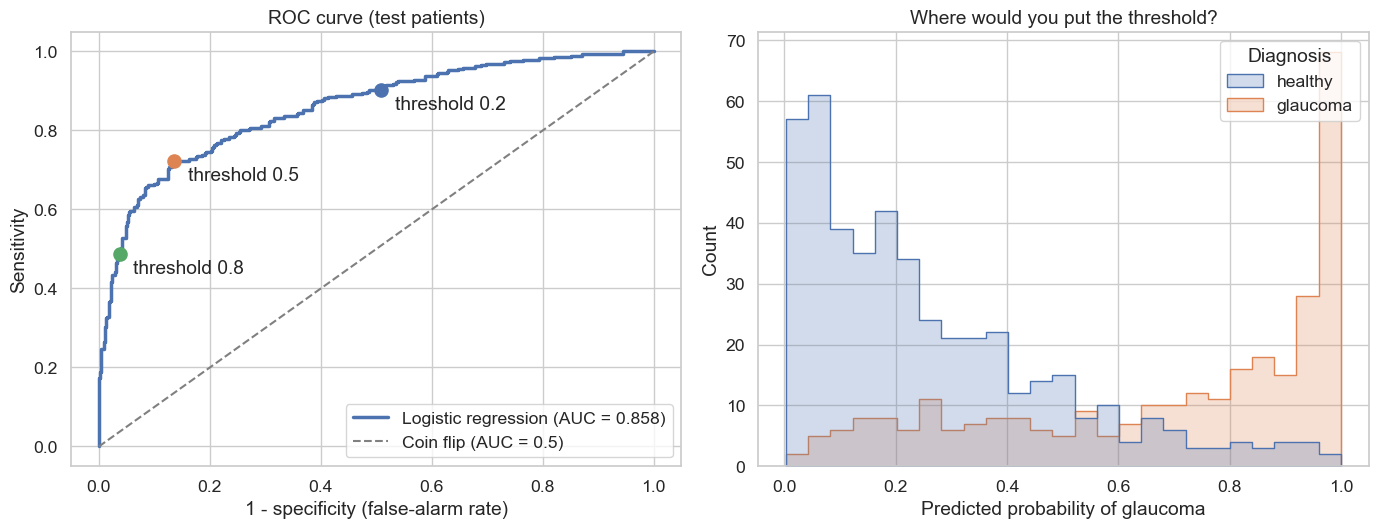

In [11]:
fpr, tpr, thr = roc_curve(y_test, proba)
auc = roc_auc_score(y_test, proba)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].plot(fpr, tpr, lw=2.5, label=f"Logistic regression (AUC = {auc:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="grey", label="Coin flip (AUC = 0.5)")
for t in (0.2, 0.5, 0.8):                              # mark three example thresholds
    k = np.argmin(abs(thr - t))
    ax[0].scatter(fpr[k], tpr[k], s=90, zorder=3)
    ax[0].annotate(f"threshold {t}", (fpr[k], tpr[k]), textcoords="offset points", xytext=(10, -14))
ax[0].set(xlabel="1 - specificity (false-alarm rate)", ylabel="Sensitivity", title="ROC curve (test patients)")
ax[0].legend(loc="lower right")

sns.histplot(x=proba, hue=y_test.map({0: "healthy", 1: "glaucoma"}), bins=25, element="step", ax=ax[1])
ax[1].set(xlabel="Predicted probability of glaucoma", title="Where would you put the threshold?")
plt.tight_layout(); plt.show()

**Your turn:** change `threshold` and watch sensitivity and specificity move in opposite directions.
Which threshold would you choose for a **screening** programme? For a **confirmatory** test? There is no
"correct" value - it depends on the cost of a missed case versus a false alarm.

In [12]:
threshold = 0.5            # <- try 0.1, 0.3, 0.7, 0.9
pred_t = (proba >= threshold).astype(int)
tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred_t, labels=[0, 1]).ravel()
clinician_metrics(tn_, fp_, fn_, tp_).round(3).to_frame(f"threshold {threshold}")

,threshold 0.5
accuracy,0.802
sensitivity (recall),0.722
specificity,0.853
PPV (precision),0.761
NPV,0.826


*Note for the public data:* even this tiny model reaches a high AUC because the label is (almost) a function of the visual field -
the circularity of B6 again. With the full field the AUC would be 1.0 and the ROC curve a right angle.

## D3. One split is one lucky (or unlucky) draw: cross-validation  *(~5 min)*
Our test accuracy depends on **which** patients ended up in the test set. **K-fold cross-validation** repeats the
split K times: every patient is in the test fold exactly once, and we look at the *spread* of the K results.
With several rows per patient we must keep each patient's rows together - `GroupKFold`.

**Preprocessing goes inside the loop.** `make_pipeline(StandardScaler(), model)` re-fits the scaler on the training
folds only - the safe way to avoid the leakage of Session 1 (B4).

In [13]:
K = 10                                       # <- 5 is common for small data, 10 for medium data
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

fold_rows = []
for k, (tr, te) in enumerate(GroupKFold(n_splits=K).split(X, y, groups), start=1):
    pipe.fit(XE.iloc[tr], y.iloc[tr])
    p = pipe.predict_proba(XE.iloc[te])[:, 1]
    fold_rows.append({"fold": k, "test rows": len(te), "test patients": groups.iloc[te].nunique(),
                      "accuracy": accuracy_score(y.iloc[te], p >= 0.5),
                      "AUC": roc_auc_score(y.iloc[te], p)})
cv = pd.DataFrame(fold_rows)
print(cv.round(3).to_string(index=False))
print(f"\nAccuracy: mean {cv['accuracy'].mean():.3f}   SD {cv['accuracy'].std():.3f}   "
      f"(min {cv['accuracy'].min():.3f}, max {cv['accuracy'].max():.3f})")
print(f"AUC:      mean {cv['AUC'].mean():.3f}   SD {cv['AUC'].std():.3f}")

 fold  test rows  test patients  accuracy   AUC
    1        170            100     0.806 0.885
    2        170            100     0.765 0.876
    3        170            100     0.800 0.890
    4        170            100     0.882 0.936
    5        170            100     0.806 0.872
    6        170            100     0.735 0.774
    7        169            100     0.811 0.887
    8        169            100     0.799 0.851
    9        169            100     0.793 0.861
   10        169            100     0.799 0.780

Accuracy: mean 0.800   SD 0.037   (min 0.735, max 0.882)
AUC:      mean 0.861   SD 0.050


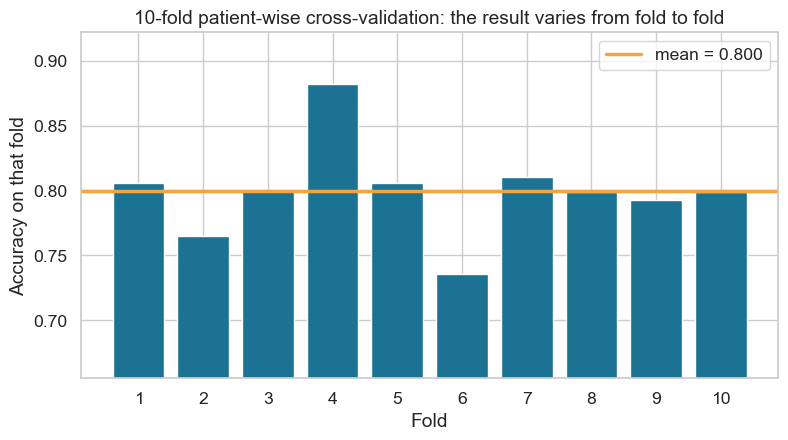

In [14]:
plt.figure(figsize=(9, 4.5))
plt.bar(cv["fold"], cv["accuracy"], color="#1C7293")
plt.axhline(cv["accuracy"].mean(), color="#F2A541", lw=2.5, label=f"mean = {cv['accuracy'].mean():.3f}")
plt.ylim(max(0, cv["accuracy"].min() - 0.08), min(1.02, cv["accuracy"].max() + 0.04))
plt.xticks(cv["fold"]); plt.xlabel("Fold"); plt.ylabel("Accuracy on that fold"); plt.legend()
plt.title(f"{K}-fold patient-wise cross-validation: the result varies from fold to fold")
plt.show()

**Your turn:** change `K` (try 3, 5, 10) and re-run. More folds = more training data per fold but more computation.
**Why not use the folds to pick the best model and then report the same number?** Choosing a model or setting on the
same folds you report is a mild form of leakage - for tuning, use a separate (nested) loop or a final untouched test set.

## D4. How sure are we? Bootstrapped confidence intervals  *(~5 min)*
A test accuracy of 0.93 from a few hundred patients is an **estimate**, not a fact. The **bootstrap** gives an
uncertainty range without any formula: *draw the test patients again, with replacement, many times, recompute the metric each time,*
and read off the middle 95 % of the results.

Important for clinical data: resample **patients**, not rows - otherwise the CI is too narrow (the rows of one patient
are not independent).

In [15]:
rng = np.random.default_rng(SEED)
test_df = pd.DataFrame({"patient": groups.iloc[test_idx].values, "y": y_test.values, "p": proba})
by_patient = {pid: g for pid, g in test_df.groupby("patient")}
patients = np.array(list(by_patient))

N_BOOT = 1000                                          # <- try 200 and 5000
boot_acc, boot_auc, boot_sens, boot_spec = [], [], [], []
for _ in range(N_BOOT):
    sample = rng.choice(patients, size=len(patients), replace=True)           # draw PATIENTS with replacement
    b = pd.concat([by_patient[pid] for pid in sample])
    if b["y"].nunique() < 2:
        continue
    pr = (b["p"] >= 0.5).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(b["y"], pr, labels=[0, 1]).ravel()
    boot_acc.append((tp_ + tn_) / len(b)); boot_auc.append(roc_auc_score(b["y"], b["p"]))
    boot_sens.append(tp_ / (tp_ + fn_)); boot_spec.append(tn_ / (tn_ + fp_))

def ci(v): return np.percentile(v, [2.5, 97.5])
summary = pd.DataFrame({
    "estimate (test set)": [accuracy_score(y_test, proba >= 0.5), auc, tp / (tp + fn), tn / (tn + fp)],
    "95% CI lower": [ci(v)[0] for v in (boot_acc, boot_auc, boot_sens, boot_spec)],
    "95% CI upper": [ci(v)[1] for v in (boot_acc, boot_auc, boot_sens, boot_spec)]},
    index=["accuracy", "AUC", "sensitivity", "specificity"])
summary.round(3)

,estimate (test set),95% CI lower,95% CI upper
accuracy,0.802,0.759,0.841
AUC,0.858,0.816,0.901
sensitivity,0.722,0.639,0.799
specificity,0.853,0.812,0.891


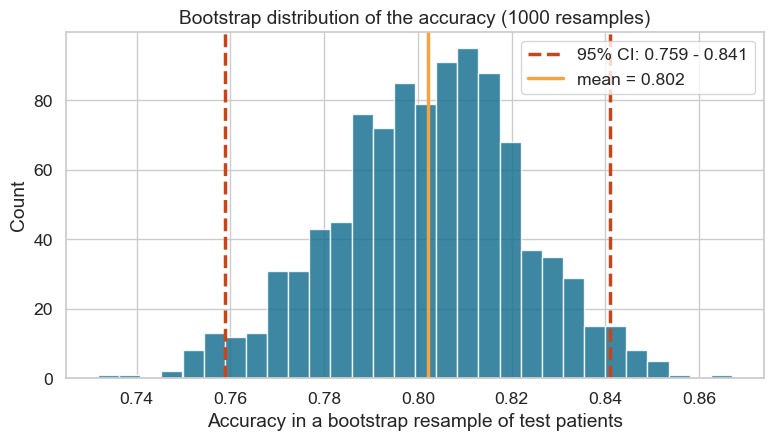

In [16]:
plt.figure(figsize=(9, 4.5))
plt.hist(boot_acc, bins=30, color="#1C7293", alpha=0.85)
lo, hi = ci(boot_acc)
plt.axvline(lo, color="#C8441B", lw=2.5, ls="--"); plt.axvline(hi, color="#C8441B", lw=2.5, ls="--", label=f"95% CI: {lo:.3f} - {hi:.3f}")
plt.axvline(np.mean(boot_acc), color="#F2A541", lw=2.5, label=f"mean = {np.mean(boot_acc):.3f}")
plt.xlabel("Accuracy in a bootstrap resample of test patients"); plt.ylabel("Count"); plt.legend()
plt.title(f"Bootstrap distribution of the accuracy ({N_BOOT} resamples)")
plt.show()

**Reading it like a paper:** *"Sensitivity 0.9x (95 % CI 0.8x-0.9x), specificity 0.9x (95 % CI ...) on N unseen test patients (patient-wise split)."*
A good result report always has: **metric + confidence interval + how the split was done + a baseline**. If two models'
intervals overlap heavily, the data do not show that one is better.

**Your turn:** use `N_BOOT = 200` vs `5000`, or make the test set smaller (`test_size=0.10` in the recap cell) - how does the interval change?
Small test sets give wide intervals: that is the honest message.

## D5. Putting it together: a mini report  *(~1 min)*

In [17]:
report = pd.DataFrame({
    "model": ["Always predict majority", "Logistic regression (patient-wise test set)", f"Logistic regression ({K}-fold CV, mean)"],
    "accuracy": [accuracy_score(y_test, b_pred), accuracy_score(y_test, proba >= 0.5), cv["accuracy"].mean()],
    "AUC": [0.5, auc, cv["AUC"].mean()]}).round(3)
report

,model,accuracy,AUC
0,Always predict majority,0.607,0.500
1,Logistic regression (patient-wise test set),0.802,0.858
2,"Logistic regression (10-fold CV, mean)",0.800,0.861


### Take-home messages
1. Report **sensitivity and specificity** (and PPV for the clinical setting) - not accuracy alone - and always compare with a **baseline**.
2. The **threshold** is a clinical decision: the ROC curve shows all trade-offs at once.
3. Use **patient-wise cross-validation** with preprocessing inside the pipeline - one split is one draw.
4. Add a **confidence interval** (bootstrap patients) - small test sets mean wide intervals.
5. A result that is *too good* is a reason to ask how the label was defined (circularity).

## Coming next (Session 3): regression metrics (MAE, RMSE, R-squared) and a first look at neural networks and computer vision.

## References & data
- **Harvard-GDP**: Luo Y, Shi M, Tian Y, Elze T, Wang M. *Harvard Glaucoma Detection and Progression: A Multimodal Multitask
  Dataset and Generalization-Reinforced Semi-Supervised Learning.* ICCV 2023. License: CC BY-NC-ND 4.0, non-commercial use.
  Source: https://huggingface.co/datasets/harvardairobotics/Harvard-GDP  (this notebook only reads the small metadata CSV).
- Follow-up visits in the recap are **simulated** for teaching purposes.
- Libraries: pandas, NumPy, Matplotlib, seaborn, scikit-learn.

*Teaching material only - the models are simplified examples, not validated clinical tools.*